# Rakuten Multimodal Product Classification

Fusion of the two single-modality models: EfficientNet-B0 (image) and XLM-RoBERTa (text).
Both pretrained branches stay frozen; only the fusion head on top is trained.

# 1. Setup and Imports

`torch` and the device are initialised **before** all other imports. On Apple Silicon (MPS) a
different import order can cause segfaults inside Jupyter.

In [1]:
import os

os.chdir(os.path.expanduser('~/Desktop/Alles/Liora/Rakuten_Project'))  # change to your specific path
BASE_DIR = os.getcwd()
IMAGES_DIR = os.path.join(BASE_DIR, 'images')
DATA_DIR = os.path.join(BASE_DIR, 'text')
IMAGES_CROPPED_DIR = os.path.join(BASE_DIR, 'images', 'cropped_image_train')
IMAGES_CROPPED_DIR_TEST = os.path.join(BASE_DIR, 'images', 'cropped_image_test')

In [2]:
import torch

device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
print(device)

mps


In [ ]:
import random
import re

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import timm
import torch.nn as nn
from bs4 import BeautifulSoup
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from transformers import AutoModel, AutoTokenizer

NUM_CLASSES = 27
IMAGE_FEATURE_DIM = 1280   # EfficientNet-B0 after global_pool
TEXT_FEATURE_DIM = 768     # XLM-RoBERTa CLS token
FUSION_DIM = IMAGE_FEATURE_DIM + TEXT_FEATURE_DIM

IMAGE_CKPT = 'final_image_model.pth'
TEXT_CKPT = 'new_xlm_roberta_best_bs.pt'
MULTIMODAL_CKPT = 'multimodal_model.pth'
CROSSATTN_CKPT = 'crossattention_model.pth'
FEATURE_CACHE = 'fusion_features.pt'

# num_workers>0 decodes images in parallel processes instead of blocking the main
# process while the GPU idles.
NUM_WORKERS = 4
LOADER_KWARGS = dict(num_workers=NUM_WORKERS, persistent_workers=NUM_WORKERS > 0)


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

# 2. Text Preprocessing and Data Preparation

The text cleaning is taken from the text workstream, so the multimodal model sees exactly the same
input the standalone XLM-RoBERTa was trained on.

**Important:** the *same* function is applied to train and test.

In [4]:
def combine_text_columns(df, text_columns=('designation', 'description')):
    """Combine designation + description into one column.
    description is missing ~35% of the time, designation never -> fillna first."""
    df[text_columns[0]] = df[text_columns[0]].fillna('')
    df[text_columns[1]] = df[text_columns[1]].fillna('')
    df['text'] = df[text_columns[0]] + ' ' + df[text_columns[1]]
    return df


def clean_text(text):
    if not isinstance(text, str):
        return ''

    # Strip HTML tags and decode entities (&eacute;, &amp;, ...).
    # BeautifulSoup handles malformed/nested tags and entity decoding,
    # which a plain `<.*?>` regex cannot do reliably.
    text = BeautifulSoup(text, "html.parser").get_text(separator=" ")

    text = re.sub(r'http\S+|www\.\S+', ' ', text)   # remove URLs
    text = re.sub(r'\S+@\S+', ' ', text)             # remove email addresses

    # Collapse whitespace only. Do NOT lowercase, strip accents, remove
    # digits/punctuation or stopwords - the transformer needs them.
    text = re.sub(r'\s+', ' ', text).strip()

    return text


def preprocess_text(df):
    df = combine_text_columns(df)
    df['text'] = df['text'].apply(clean_text)
    return df


def add_image_path(df, images_dir):
    """os.listdir() does not preserve the DataFrame order, so the image is linked
    to its row through the file name built from imageid / productid."""
    df['image_path'] = (
        images_dir + '/image_' + df['imageid'].astype(str)
        + '_product_' + df['productid'].astype(str) + '.jpg'
    )
    missing = (~df['image_path'].apply(os.path.exists)).sum()
    print(f"rows: {len(df)} | missing image files: {missing}")
    assert missing == 0, "Some image paths do not exist - run the cropping step first."
    return df

In [5]:
df = pd.read_csv(DATA_DIR + '/X_train_update.csv')
df = preprocess_text(df)
df = add_image_path(df, IMAGES_CROPPED_DIR)

y = pd.read_csv(DATA_DIR + '/Y_train_CVw08PX.csv')
df = df.merge(y, on='Unnamed: 0')

df[['designation', 'text', 'image_path', 'prdtypecode']].head()

# 3. Model Definitions

## Text branch

Same architecture as in the text workstream, so the trained checkpoint fits into it.

In [9]:
class XLMRoBERTaClassifier(nn.Module):
    def __init__(self, num_classes, dropout=0.3):
        super().__init__()
        self.bert = AutoModel.from_pretrained("xlm-roberta-base")
        self.drop = nn.Dropout(dropout)
        self.classifier = nn.Linear(self.bert.config.hidden_size, num_classes)

    def forward(self, input_ids, attention_mask):
        out = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        cls = out.last_hidden_state[:, 0, :]
        cls = self.drop(cls)
        return self.classifier(cls)

## Fusion head and fusion model

The head is factored out into its own module. That is what makes the cached-feature training
possible: the exact same `FusionHead` can be trained either on precomputed features or as part of
the full `MultimodalClassifier`, and the weights are interchangeable between the two.

The backbone forwards run inside `torch.no_grad()`. Both branches are frozen, so there is nothing
to backpropagate into them and no reason to keep their activations around.

In [10]:
class FusionHead(nn.Module):
    """image features (1280) + text CLS (768) -> 27 classes."""
    def __init__(self, in_dim=FUSION_DIM, num_classes=NUM_CLASSES, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 512),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        return self.net(x)


class MultimodalClassifier(nn.Module):
    def __init__(self, image_model, text_model, num_classes=NUM_CLASSES):
        super().__init__()
        self.image_model = image_model
        self.text_model = text_model

        # Freeze both pretrained branches completely
        for param in self.image_model.parameters():
            param.requires_grad = False
        for param in self.text_model.parameters():
            param.requires_grad = False

        combined_size = self.image_model.num_features + self.text_model.bert.config.hidden_size
        self.head = FusionHead(in_dim=combined_size, num_classes=num_classes)

    def extract_features(self, image, input_ids, attention_mask):
        """The frozen part. Identical to what the feature cache stores, so a head
        trained on cached features can be dropped into this model unchanged."""
        with torch.no_grad():
            image_features = self.image_model.forward_features(image)
            image_features = self.image_model.global_pool(image_features)

            text_output = self.text_model.bert(input_ids=input_ids,
                                               attention_mask=attention_mask)
            text_features = text_output.last_hidden_state[:, 0, :]

        return torch.cat([image_features, text_features], dim=1)

    def forward(self, image, input_ids, attention_mask):
        return self.head(self.extract_features(image, input_ids, attention_mask))

## Load the two trained branches

In [11]:
def build_image_branch():
    model = timm.create_model('efficientnet_b0', pretrained=True, num_classes=NUM_CLASSES)
    model.classifier = nn.Sequential(
        nn.Linear(1280, 512), nn.ReLU(), nn.Dropout(0.3), nn.Linear(512, NUM_CLASSES)
    )
    model.load_state_dict(torch.load(IMAGE_CKPT, map_location='cpu'))
    return model.to(device).eval()


def build_text_branch(num_classes):
    model = XLMRoBERTaClassifier(num_classes)
    model.load_state_dict(torch.load(TEXT_CKPT, map_location='cpu'))
    return model.to(device).eval()


le = joblib.load('label_encoder.pkl')
num_classes = len(le.classes_)
assert num_classes == NUM_CLASSES

image_model = build_image_branch()
text_model = build_text_branch(num_classes)

multimodal_model = MultimodalClassifier(image_model, text_model).to(device)

trainable = sum(p.numel() for p in multimodal_model.parameters() if p.requires_grad)
total = sum(p.numel() for p in multimodal_model.parameters())
print(f"{trainable:,} out of {total:,} parameters trainable ({100*trainable/total:.1f}%)")

/Users/thomasmaisch/Desktop/Alles/Liora/Rakuten_Project/venv/lib/python3.11/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator LabelEncoder from version 1.6.1 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


1,062,939 out of 283,804,621 parameters trainable (0.4%)


# 4. Datasets and Loaders

In [13]:
y_encoded = le.transform(df['prdtypecode'])

X_train_img, X_val_img, X_train_text, X_val_text, y_train, y_val = train_test_split(
    df['image_path'], df['text'], y_encoded,
    test_size=0.20, random_state=42, stratify=y_encoded
)

print(f"train: {len(X_train_img)} | val: {len(X_val_img)}")

train: 67932 | val: 16984


In [14]:
# timm exposes the preprocessing the pretrained image model was trained with
_reference_model = timm.create_model('efficientnet_b0', pretrained=True, num_classes=NUM_CLASSES)
data_config = timm.data.resolve_data_config({}, model=_reference_model)
del _reference_model
print(data_config)

transform_train = transforms.Compose([
    transforms.Resize((224, 224), interpolation=transforms.InterpolationMode.BICUBIC),
    transforms.RandomRotation(10),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=data_config['mean'], std=data_config['std'])
])

transform_val = transforms.Compose([
    transforms.Resize((224, 224), interpolation=transforms.InterpolationMode.BICUBIC),
    transforms.ToTensor(),
    transforms.Normalize(mean=data_config['mean'], std=data_config['std'])
])

tokenizer = AutoTokenizer.from_pretrained("xlm-roberta-base")

{'input_size': (3, 224, 224), 'interpolation': 'bicubic', 'mean': (0.485, 0.456, 0.406), 'std': (0.229, 0.224, 0.225), 'crop_pct': 0.875, 'crop_mode': 'center'}


In [25]:
class MultimodalDataset(Dataset):
    """labels=None -> test mode: a dummy label of -1 is returned so the batch
    structure stays identical and the same loops can be reused."""

    def __init__(self, image_paths, texts, labels, tokenizer, transform=None, max_length=128):
        self.image_paths = image_paths.tolist()
        self.texts = texts.tolist()
        self.labels = labels
        self.tokenizer = tokenizer
        self.transform = transform
        self.max_length = max_length

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image = Image.open(self.image_paths[idx]).convert('RGB')
        if self.transform:
            image = self.transform(image)

        encoding = self.tokenizer(
            self.texts[idx], padding='max_length', truncation=True,
            max_length=self.max_length, return_tensors='pt'
        )
        input_ids = encoding['input_ids'].squeeze(0)
        attention_mask = encoding['attention_mask'].squeeze(0)

        label = -1 if self.labels is None else self.labels[idx]

        return image, input_ids, attention_mask, label


def make_loader(images, texts, labels, transform, batch_size=32, shuffle=False):
    dataset = MultimodalDataset(images, texts, labels, tokenizer, transform=transform)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, **LOADER_KWARGS)

# 5. Feature Cache

Both backbones are frozen, so for a given image and text they always produce the same feature
vector. Recomputing them every epoch is pure waste: **283M parameters** are evaluated to feed a
head with **~1M**.

The features are therefore extracted **once** and cached. The head then trains on tensors that
already sit on the GPU — no image decoding, no transformer forward, no DataLoader in the loop.

The one thing this gives up is image augmentation: a random crop would be frozen into the cache as
one arbitrary draw. Section 7 keeps the end-to-end loop for that case, so both routes are available
and can be compared.

In [30]:
@torch.no_grad()
def extract_features(loader, name, image_model, text_model):
    """Run both frozen backbones once and cache their outputs."""
    image_model.eval()
    text_model.eval()

    img_all, txt_all, lab_all = [], [], []

    for i, (images, input_ids, attention_mask, labels) in enumerate(loader):
        images = images.to(device)
        input_ids = input_ids.to(device)
        attention_mask = attention_mask.to(device)

        # exactly the same extraction as MultimodalClassifier.extract_features
        f_img = image_model.global_pool(image_model.forward_features(images))  # (B, 1280)
        f_txt = text_model.bert(input_ids=input_ids,
                                attention_mask=attention_mask
                                ).last_hidden_state[:, 0, :]                   # (B,  768)

        img_all.append(f_img.cpu())
        txt_all.append(f_txt.cpu())
        lab_all.append(labels)

        if i % 50 == 0:
            print(f"  {name}: batch {i}/{len(loader)}")

    return torch.cat(img_all), torch.cat(txt_all), torch.cat(lab_all)

In [ ]:
# transform_val for BOTH splits: no augmentation, since a random draw would be
# baked into the cache. shuffle=False so nothing can silently misalign.
feat_train_loader = make_loader(X_train_img, X_train_text, y_train, transform_val,
                                batch_size=64, shuffle=False)
feat_val_loader = make_loader(X_val_img, X_val_text, y_val, transform_val,
                              batch_size=64, shuffle=False)

if os.path.exists(FEATURE_CACHE):
    cache = torch.load(FEATURE_CACHE)
    F_tr, lab_tr, F_va, lab_va = cache['F_tr'], cache['lab_tr'], cache['F_va'], cache['lab_va']
    assert len(F_va) == len(X_val_img), (
        f"Cache hat {len(F_va)} Val-Beispiele, aktueller Split hat {len(X_val_img)} - "
        f"Cache ist veraltet. Lösche {FEATURE_CACHE} und lass diese Zelle neu laufen."
    )
    print(f"loaded cache from {FEATURE_CACHE}")
else:
    print("Extracting train features...")
    img_tr, txt_tr, lab_tr = extract_features(feat_train_loader, "train", image_model, text_model)
    print("Extracting val features...")
    img_va, txt_va, lab_va = extract_features(feat_val_loader, "val", image_model, text_model)

    # Concatenate in the SAME order the model uses: [image | text]
    F_tr = torch.cat([img_tr, txt_tr], dim=1)
    F_va = torch.cat([img_va, txt_va], dim=1)

    torch.save({'F_tr': F_tr, 'lab_tr': lab_tr, 'F_va': F_va, 'lab_va': lab_va}, FEATURE_CACHE)
    print(f"cached to {FEATURE_CACHE}")

IMG_SLICE = slice(0, IMAGE_FEATURE_DIM)
TXT_SLICE = slice(IMAGE_FEATURE_DIM, FUSION_DIM)

print("train:", tuple(F_tr.shape), "| val:", tuple(F_va.shape))

Extracting train features...
  train: batch 0/1062
  train: batch 50/1062
  train: batch 100/1062
  train: batch 150/1062
  train: batch 200/1062
  train: batch 250/1062
  train: batch 300/1062
  train: batch 350/1062
  train: batch 400/1062
  train: batch 450/1062
  train: batch 500/1062
  train: batch 550/1062
  train: batch 600/1062
  train: batch 650/1062
  train: batch 700/1062
  train: batch 750/1062
  train: batch 800/1062
  train: batch 850/1062
  train: batch 900/1062
  train: batch 950/1062
  train: batch 1000/1062
  train: batch 1050/1062
Extracting val features...
  val: batch 0/266
  val: batch 50/266
  val: batch 100/266
  val: batch 150/266
  val: batch 200/266
  val: batch 250/266
cached to fusion_features.pt
train: (67932, 2048) | val: (16984, 2048)


# 6. Training the Fusion Head (on cached features)

The data is a tensor that already lives on the GPU, so an epoch is a handful of matrix multiplications.

Early stopping runs on the validation loss; the checkpoint is kept on the best **F1**. The two are
deliberately independent, since the lowest-loss epoch is not always the best-F1 epoch.

In [33]:
def mask_features(F, mode):
    """Zero out one modality. Returns a COPY -- never modify the cache in place."""
    F = F.clone()
    if mode == 'text_only':
        F[:, IMG_SLICE] = 0.0        # image ablated
    elif mode == 'image_only':
        F[:, TXT_SLICE] = 0.0        # text ablated
    elif mode != 'both':
        raise ValueError(mode)
    return F


def train_head(mode='both', num_epochs=150, patience=5, lr=2e-5, batch_size=32,
               seed=42, verbose=False):
    """Train a FusionHead on the cached features.
    Returns (best_f1, best_state_dict, best_preds, history)."""
    set_seed(seed)

    head = FusionHead().to(device)

    # Everything moves to the device ONCE - no DataLoader, no per-batch host->device copy
    Xtr = mask_features(F_tr, mode).float().to(device)
    ytr = lab_tr.long().to(device)
    Xva = mask_features(F_va, mode).float().to(device)
    yva = lab_va.long().to(device)

    n = Xtr.size(0)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(head.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.5, patience=2)

    best_val_loss, best_f1, counter = float('inf'), 0.0, 0
    best_state, best_preds = None, None
    history = {'train_loss': [], 'val_loss': [], 'train_f1': [], 'f1': [], 'accuracy': []}

    for epoch in range(num_epochs):
        head.train()
        perm = torch.randperm(n, device=device)          # shuffle by index
        train_loss = 0.0
        tr_preds = torch.empty(n, dtype=torch.long, device=device)

        for i in range(0, n, batch_size):
            idx = perm[i:i + batch_size]
            optimizer.zero_grad()
            out = head(Xtr[idx])
            loss = criterion(out, ytr[idx])
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * idx.size(0)
            tr_preds[idx] = out.argmax(1).detach()

        avg_train_loss = train_loss / n
        train_f1 = f1_score(ytr.cpu().numpy(), tr_preds.cpu().numpy(), average='weighted')

        # Validation in ONE forward pass - the val set fits comfortably on the device
        head.eval()
        with torch.no_grad():
            out = head(Xva)
            avg_val_loss = criterion(out, yva).item()
            preds = out.argmax(1).cpu().numpy()

        labs = yva.cpu().numpy()
        f1 = f1_score(labs, preds, average='weighted')
        accuracy = (preds == labs).mean()

        history['train_loss'].append(avg_train_loss)
        history['val_loss'].append(avg_val_loss)
        history['train_f1'].append(train_f1)
        history['f1'].append(f1)
        history['accuracy'].append(accuracy)

        scheduler.step(avg_val_loss)

        if verbose:
            print(f"Epoch {epoch+1}/{num_epochs} | Train Loss: {avg_train_loss:.4f} | "
                  f"Val Loss: {avg_val_loss:.4f} | Train F1: {train_f1:.4f} | "
                  f"Val Accuracy: {accuracy:.4f} | F1 Score: {f1:.4f}")

        if f1 > best_f1:
            best_f1 = f1
            best_preds = preds
            best_state = {k: v.detach().cpu().clone() for k, v in head.state_dict().items()}

        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            counter = 0
        else:
            counter += 1
            if counter >= patience:
                break

    print(f"{mode:>12} | best weighted F1 = {best_f1:.4f}  ({epoch+1} epochs)")
    return best_f1, best_state, best_preds, history

In [34]:
best_f1, best_state, _, history = train_head('both', verbose=True)

# The head trained on cached features IS the head of the full model - same module,
# same shapes. Load it back in and save the complete multimodal checkpoint.
multimodal_model.head.load_state_dict(best_state)
torch.save(multimodal_model.state_dict(), MULTIMODAL_CKPT)
print(f"\nBest weighted F1: {best_f1:.4f} -> saved to {MULTIMODAL_CKPT}")

Epoch 1/150 | Train Loss: 0.4871 | Val Loss: 0.3564 | Train F1: 0.9093 | Val Accuracy: 0.8900 | F1 Score: 0.8899
Epoch 2/150 | Train Loss: 0.1791 | Val Loss: 0.3488 | Train F1: 0.9443 | Val Accuracy: 0.8942 | F1 Score: 0.8942
Epoch 3/150 | Train Loss: 0.1614 | Val Loss: 0.3475 | Train F1: 0.9494 | Val Accuracy: 0.8947 | F1 Score: 0.8947
Epoch 4/150 | Train Loss: 0.1518 | Val Loss: 0.3472 | Train F1: 0.9514 | Val Accuracy: 0.8958 | F1 Score: 0.8955
Epoch 5/150 | Train Loss: 0.1448 | Val Loss: 0.3484 | Train F1: 0.9542 | Val Accuracy: 0.8957 | F1 Score: 0.8958
Epoch 6/150 | Train Loss: 0.1380 | Val Loss: 0.3537 | Train F1: 0.9560 | Val Accuracy: 0.8968 | F1 Score: 0.8971
Epoch 7/150 | Train Loss: 0.1334 | Val Loss: 0.3505 | Train F1: 0.9569 | Val Accuracy: 0.8978 | F1 Score: 0.8978
Epoch 8/150 | Train Loss: 0.1277 | Val Loss: 0.3520 | Train F1: 0.9586 | Val Accuracy: 0.8984 | F1 Score: 0.8984
Epoch 9/150 | Train Loss: 0.1254 | Val Loss: 0.3521 | Train F1: 0.9591 | Val Accuracy: 0.8975 | 

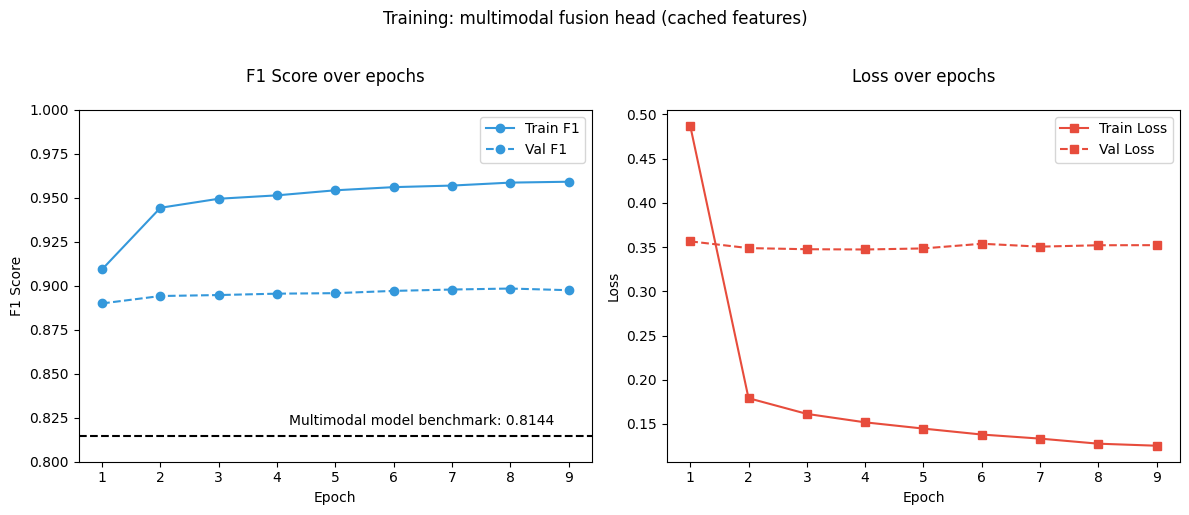

In [35]:
MULTIMODAL_BENCHMARK = 0.8144  # standalone XLM-RoBERTa (text only)


def plot_history(history, title, benchmark=None, benchmark_label=None, ylim=(0.8, 1.0)):
    """Reads the epoch count from the data, so it works no matter how many epochs
    early stopping actually ran."""
    epochs = range(1, len(history['train_loss']) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].plot(epochs, history['train_f1'], color='#3498db', marker='o', label='Train F1')
    axes[0].plot(epochs, history['f1'], color='#3498db', marker='o',
                 linestyle='--', label='Val F1')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('F1 Score')
    axes[0].set_title('F1 Score over epochs', pad=20)
    axes[0].set_ylim(*ylim)
    axes[0].legend()

    if benchmark is not None:
        axes[0].axhline(y=benchmark, color='black', linestyle='--', linewidth=1.5)
        axes[0].text(len(history['train_loss']) - 0.25, benchmark + 0.005,
                     f'{benchmark_label}: {benchmark:.4f}',
                     ha='right', va='bottom', color='black', fontsize=10)

    axes[1].plot(epochs, history['train_loss'], color='#e74c3c', marker='s', label='Train Loss')
    axes[1].plot(epochs, history['val_loss'], color='#e74c3c', marker='s',
                 linestyle='--', label='Val Loss')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].set_title('Loss over epochs', pad=20)
    axes[1].legend()

    plt.suptitle(title, y=1.02)
    plt.tight_layout()
    plt.show()


plot_history(history, 'Training: multimodal fusion head (cached features)',
             benchmark=MULTIMODAL_BENCHMARK, benchmark_label='Multimodal model benchmark')

# 7. End-to-End Training (optional)

Only needed if the image branch should see **augmented** images — that is the one thing the cache
cannot do. Everything else is identical: same head, same frozen backbones, same schedule.

The frozen backbones are explicitly kept in `eval()` mode inside the loop. Otherwise BatchNorm in
EfficientNet keeps updating its running statistics and dropout in RoBERTa fires, which silently
corrupts the very features that are being fused.

In [ ]:
def train_end_to_end(model, train_loader, val_loader, num_epochs=40, patience=5,
                    lr=2e-5, save_path=None, seed=42):
    set_seed(seed)

    criterion = nn.CrossEntropyLoss()
    # Only the ~1M trainable parameters, not the 283M frozen ones
    optimizer = torch.optim.Adam(
        [p for p in model.parameters() if p.requires_grad], lr=lr
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.5, patience=2)

    best_val_loss, best_f1, patience_counter = float('inf'), 0.0, 0
    history = {'train_loss': [], 'val_loss': [], 'train_f1': [], 'f1': [], 'accuracy': []}

    for epoch in range(num_epochs):
        model.train()
        model.image_model.eval()   # keep BatchNorm running stats frozen
        model.text_model.eval()    # keep RoBERTa dropout off

        train_loss = 0.0
        tr_labels, tr_preds = [], []

        for images, input_ids, attention_mask, labels in train_loader:
            images = images.to(device)
            input_ids = input_ids.to(device)
            attention_mask = attention_mask.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(images, input_ids, attention_mask)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            train_loss += loss.item()
            tr_labels.extend(labels.cpu().numpy())
            tr_preds.extend(outputs.argmax(1).cpu().numpy())

        train_f1 = f1_score(tr_labels, tr_preds, average='weighted')

        model.eval()
        val_loss, correct, total_val = 0.0, 0, 0
        all_labels, all_predicted = [], []

        with torch.no_grad():
            for images, input_ids, attention_mask, labels in val_loader:
                images = images.to(device)
                input_ids = input_ids.to(device)
                attention_mask = attention_mask.to(device)
                labels = labels.to(device)

                outputs = model(images, input_ids, attention_mask)
                val_loss += criterion(outputs, labels).item()

                predicted = outputs.argmax(1)
                total_val += labels.size(0)
                correct += (predicted == labels).sum().item()
                all_labels.extend(labels.cpu().numpy())
                all_predicted.extend(predicted.cpu().numpy())

        avg_train_loss = train_loss / len(train_loader)
        avg_val_loss = val_loss / len(val_loader)
        accuracy = correct / total_val
        f1 = f1_score(all_labels, all_predicted, average='weighted')

        print(f"Epoch {epoch+1}/{num_epochs} | Train Loss: {avg_train_loss:.4f} | "
              f"Val Loss: {avg_val_loss:.4f} | Train F1: {train_f1:.4f} | "
              f"Val Accuracy: {accuracy:.4f} | F1 Score: {f1:.4f}")

        history['train_loss'].append(avg_train_loss)
        history['val_loss'].append(avg_val_loss)
        history['train_f1'].append(train_f1)
        history['f1'].append(f1)
        history['accuracy'].append(accuracy)

        scheduler.step(avg_val_loss)

        if f1 > best_f1:
            best_f1 = f1
            if save_path is not None:
                torch.save(model.state_dict(), save_path)

        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print("Early Stopping!")
                break

    return best_f1, history

In [ ]:
# Uncomment to train end to end WITH image augmentation and compare against the
# cached-feature result above.
#
# train_loader_aug = make_loader(X_train_img, X_train_text, y_train,
#                                transform_train, shuffle=True)
# val_loader = make_loader(X_val_img, X_val_text, y_val, transform_val)
#
# aug_model = MultimodalClassifier(build_image_branch(),
#                                  build_text_branch(num_classes)).to(device)
# f1_aug, history_aug = train_end_to_end(aug_model, train_loader_aug, val_loader,
#                                        save_path='multimodal_model_augmented.pth')
# plot_history(history_aug, 'Training: multimodal, end to end with augmentation',
#              benchmark=TEXT_BENCHMARK, benchmark_label='Text-only benchmark')

# 8. Evaluation

The best checkpoint is reloaded into a freshly built model, so the evaluation cannot accidentally
run on whatever state the last epoch left behind.

The confusion matrix is normalised **per true class** (row-wise). With absolute counts the large
classes would dominate regardless of how well they are actually classified.

In [36]:
eval_model = MultimodalClassifier(build_image_branch(),
                                  build_text_branch(num_classes)).to(device)
eval_model.load_state_dict(torch.load(MULTIMODAL_CKPT, map_location=device))
eval_model.eval()

val_loader = make_loader(X_val_img, X_val_text, y_val, transform_val)

final_labels, final_predicted = [], []

with torch.no_grad():
    for images, input_ids, attention_mask, labels in val_loader:
        outputs = eval_model(images.to(device), input_ids.to(device),
                             attention_mask.to(device))
        final_labels.extend(labels.numpy())
        final_predicted.extend(outputs.argmax(1).cpu().numpy())

print(f"weighted F1 on the validation set: "
      f"{f1_score(final_labels, final_predicted, average='weighted'):.4f}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


weighted F1 on the validation set: 0.8984


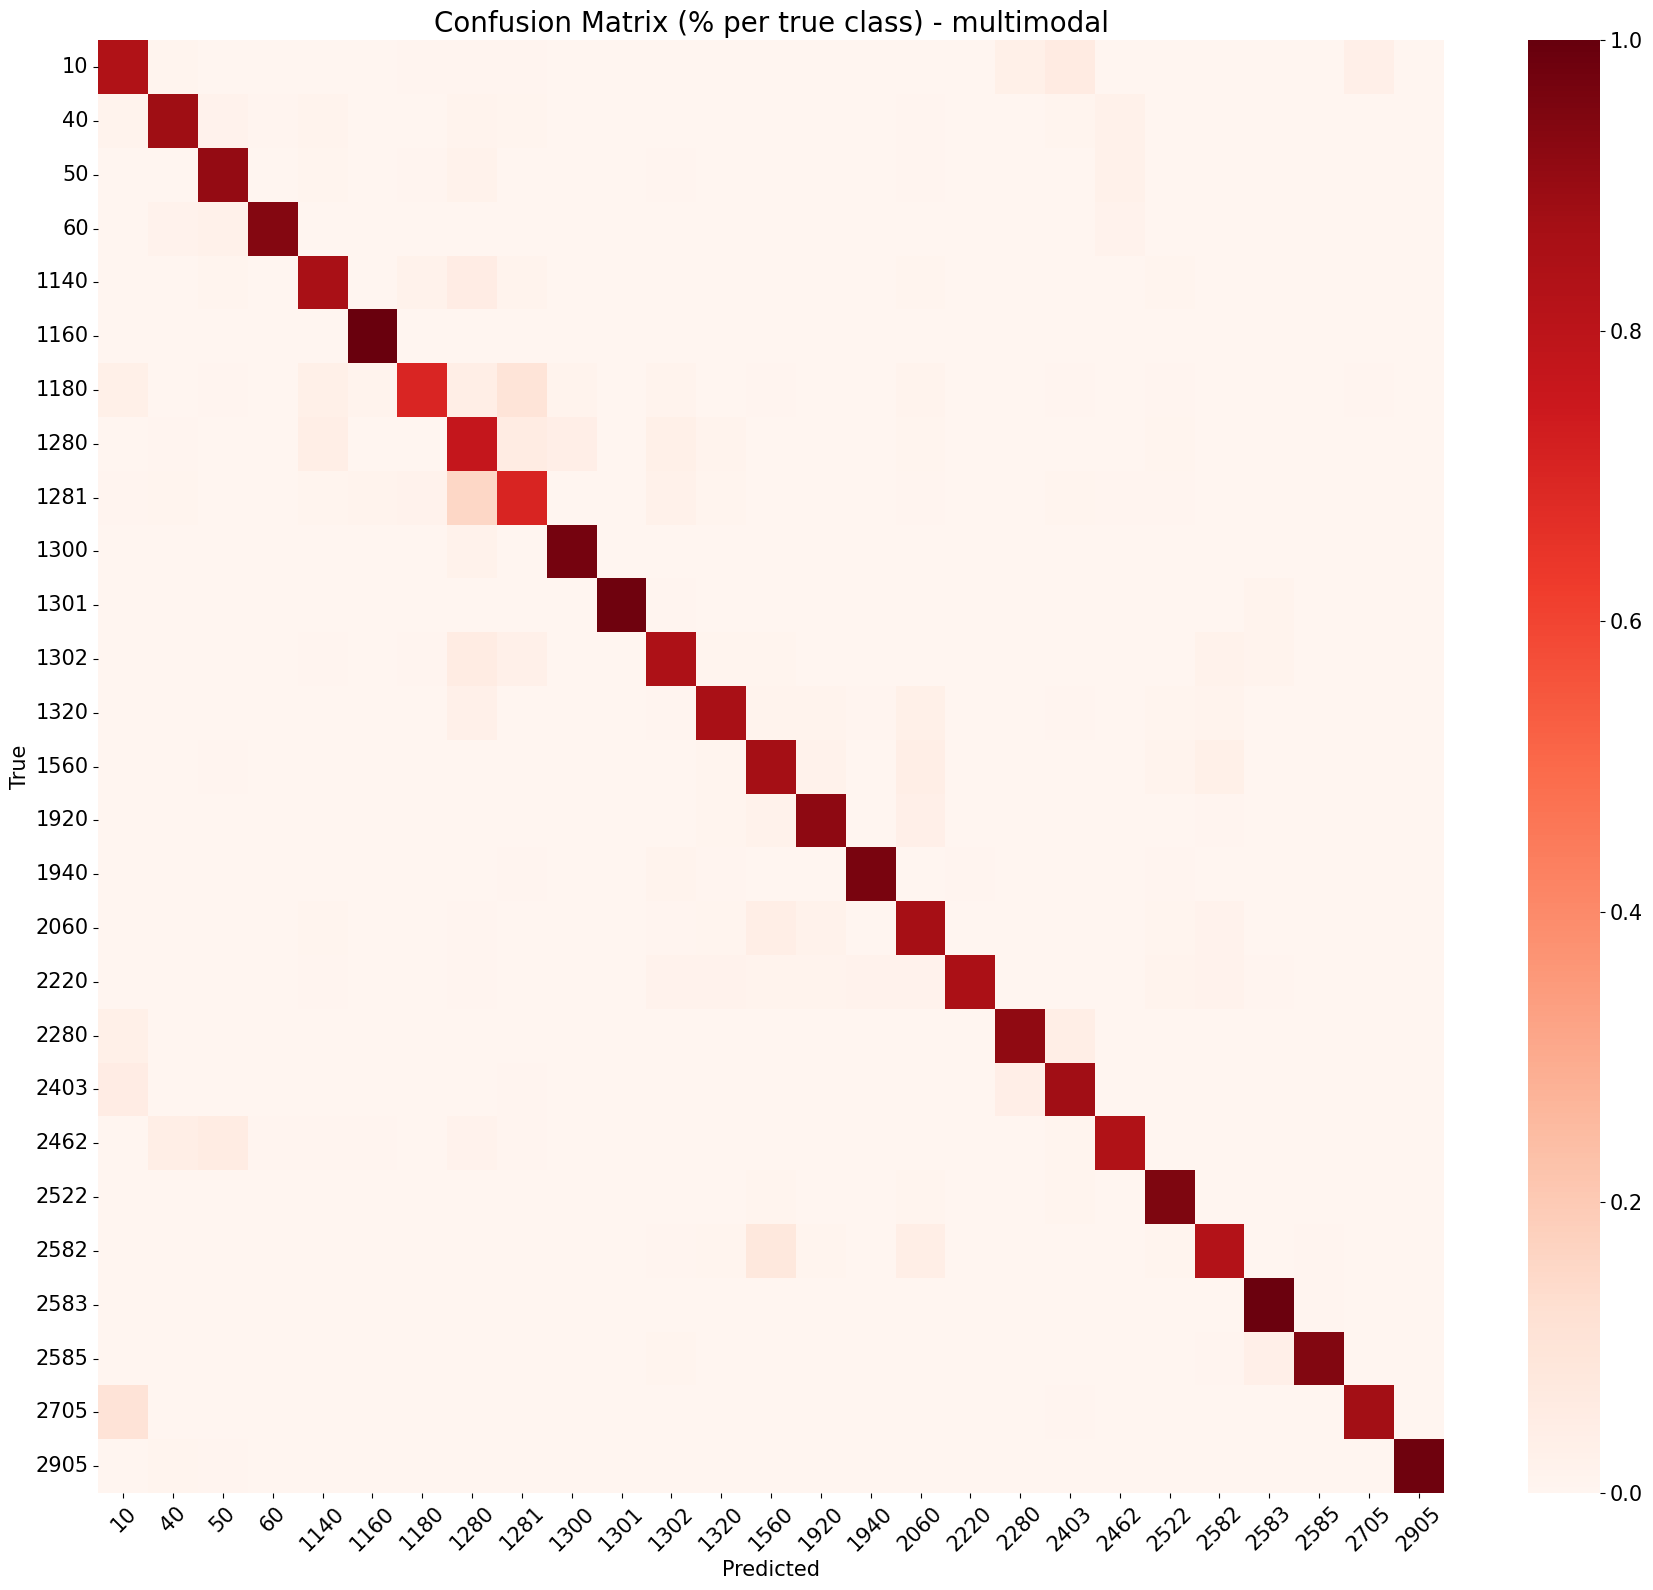

In [37]:
cm = confusion_matrix(final_labels, final_predicted)
cm_normalized = cm.astype('float') / cm.sum(axis=1, keepdims=True)
class_names = [f"{code}" for code in le.classes_]

plt.figure(figsize=(18, 16))
ax = sns.heatmap(cm_normalized, fmt='.2f', cmap='Reds', vmin=0, vmax=1,
                 xticklabels=class_names, yticklabels=class_names)

ax.collections[0].colorbar.ax.tick_params(labelsize=15)

plt.xlabel('Predicted', fontsize=15)
plt.ylabel('True', fontsize=15)
plt.title('Confusion Matrix (% per true class) - multimodal', fontsize=20)
plt.xticks(rotation=45, ha='center', fontsize=15)
plt.yticks(rotation=0, fontsize=15)
plt.tight_layout()
plt.show()

## Sanity check: did the frozen image branch really stay frozen?

Compares the BatchNorm running statistics of the standalone image model against the ones stored
inside the trained multimodal checkpoint. Any drift means the backbone was not in `eval()` mode
during training and the fused features were quietly corrupted.

In [38]:
sd_img = torch.load(IMAGE_CKPT, map_location='cpu')
sd_mm = torch.load(MULTIMODAL_CKPT, map_location='cpu')

drifts = []
for k in sd_img:
    if 'running_mean' in k or 'running_var' in k:
        a = sd_img[k]
        b = sd_mm['image_model.' + k]
        rel = (a - b).abs().mean() / (a.abs().mean() + 1e-8)
        drifts.append(rel.item())

drifts = torch.tensor(drifts)
print(f"BatchNorm buffers checked : {len(drifts)}")
print(f"mean relative drift       : {drifts.mean():.6f}")
print(f"max  relative drift       : {drifts.max():.6f}")

BatchNorm buffers checked : 98
mean relative drift       : 0.000000
max  relative drift       : 0.000000


# 9. Fusion Gain Ablation

How much does each modality actually contribute? The identical head is trained three times on the
cached features:

- `both`: image + text
- `text_only`: image features zeroed out
- `image_only`: text features zeroed out

Because the backbones are frozen, this is exact. Nothing is approximated, the ablation just skips
recomputing features that cannot change.

A single seed says nothing about whether a small gain is real, so the whole thing runs over five
seeds and the per-class F1 is collected as well.

In [39]:
SEEDS = [0, 1, 2, 42, 161]
MODES = ['both', 'text_only', 'image_only']

lab_np = lab_va.numpy()
class_str = le.classes_.astype(str)


def per_class_f1(preds):
    rep = classification_report(lab_np, preds, output_dict=True,
                                zero_division=0, target_names=class_str)
    return pd.Series({c: rep[c]['f1-score'] for c in class_str})


agg = []                            # aggregate F1 per seed
pc = {mode: [] for mode in MODES}   # per-class F1 per seed

for seed in SEEDS:
    row = {'seed': seed}
    for mode in MODES:
        f1, _, preds, _ = train_head(mode, num_epochs=150, seed=seed)
        row[mode] = f1
        pc[mode].append(per_class_f1(preds))
    agg.append(row)
    print(f"seed {seed}: both={row['both']:.4f}  text_only={row['text_only']:.4f}  "
          f"image_only={row['image_only']:.4f}  gain={row['both']-row['text_only']:+.4f}\n")

agg = pd.DataFrame(agg).set_index('seed')
print(agg.agg(['mean', 'std']).to_string(float_format='%.4f'))

        both | best weighted F1 = 0.8983  (8 epochs)
   text_only | best weighted F1 = 0.8765  (51 epochs)
  image_only | best weighted F1 = 0.6792  (7 epochs)
seed 0: both=0.8983  text_only=0.8765  image_only=0.6792  gain=+0.0218

        both | best weighted F1 = 0.8977  (8 epochs)
   text_only | best weighted F1 = 0.8762  (30 epochs)
  image_only | best weighted F1 = 0.6785  (7 epochs)
seed 1: both=0.8977  text_only=0.8762  image_only=0.6785  gain=+0.0215

        both | best weighted F1 = 0.8990  (8 epochs)
   text_only | best weighted F1 = 0.8760  (51 epochs)
  image_only | best weighted F1 = 0.6774  (7 epochs)
seed 2: both=0.8990  text_only=0.8760  image_only=0.6774  gain=+0.0229

        both | best weighted F1 = 0.8984  (9 epochs)
   text_only | best weighted F1 = 0.8758  (33 epochs)
  image_only | best weighted F1 = 0.6785  (7 epochs)
seed 42: both=0.8984  text_only=0.8758  image_only=0.6785  gain=+0.0226

        both | best weighted F1 = 0.8991  (9 epochs)
   text_only | bes


Full multimodal (image + text) : 0.8985
Text only  (image ablated)     : 0.8761   -> image contributes +0.0224
Image only (text ablated)      : 0.6787   -> text  contributes +0.2198


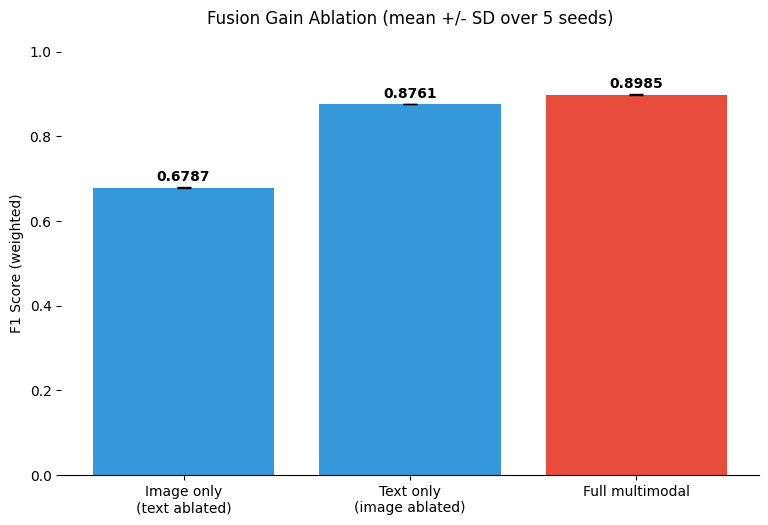

In [40]:
m, s = agg.mean(), agg.std()
order = ['image_only', 'text_only', 'both']
labels = ['Image only\n(text ablated)', 'Text only\n(image ablated)', 'Full multimodal']

print(f"\n{'='*56}")
print(f"Full multimodal (image + text) : {m['both']:.4f}")
print(f"Text only  (image ablated)     : {m['text_only']:.4f}   "
      f"-> image contributes +{m['both']-m['text_only']:.4f}")
print(f"Image only (text ablated)      : {m['image_only']:.4f}   "
      f"-> text  contributes +{m['both']-m['image_only']:.4f}")
print(f"{'='*56}")

plt.figure(figsize=(9, 5.5))
plt.bar(labels, m[order], yerr=s[order], capsize=5,
        color=['#3498db', '#3498db', '#e74c3c'])
sns.despine(left=True)
for i, k in enumerate(order):
    plt.text(i, m[k] + s[k] + 0.015, f"{m[k]:.4f}", ha='center', fontweight='bold')
plt.ylabel('F1 Score (weighted)')
plt.ylim(0, 1.0)
plt.title('Fusion Gain Ablation (mean +/- SD over 5 seeds)', pad=20)
plt.show()

2705   0.1207
10     0.1137
40     0.0979
1180   0.0942
2403   0.0411
2462   0.0391
1140   0.0351
60     0.0351
1281   0.0346
1160   0.0264
1320   0.0254
1940   0.0109
2060   0.0101
1301   0.0100
1302   0.0090
50     0.0084
1280   0.0079
2280   0.0066
2582   0.0065
2585   0.0058
2522   0.0050
2220   0.0026
1560   0.0018
1300   0.0012
2583   0.0012
1920   0.0005
2905   0.0000


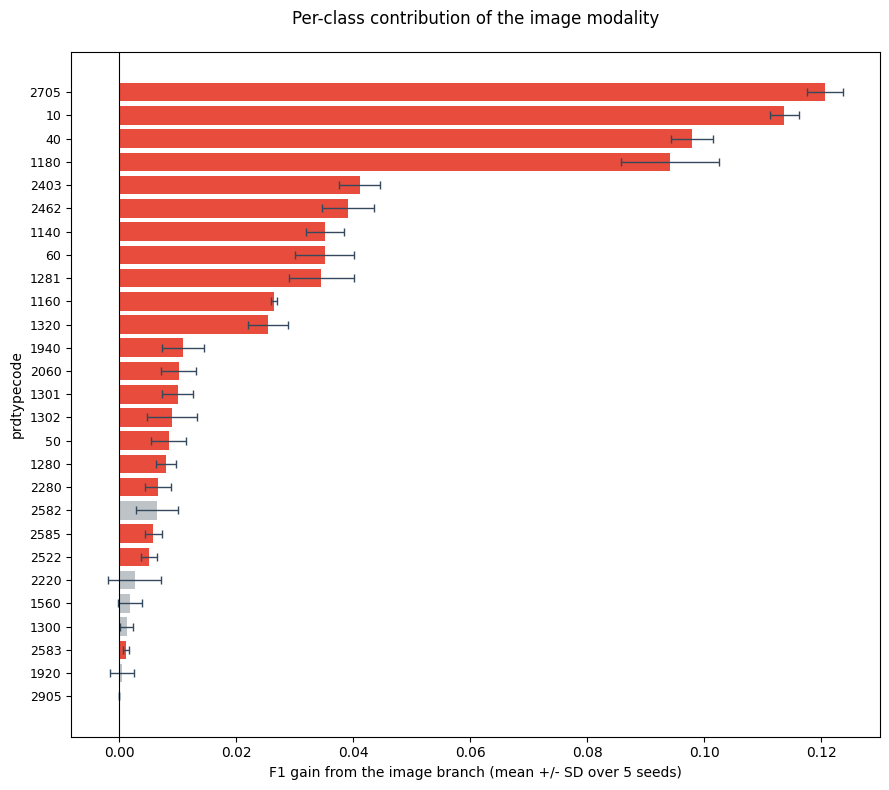

In [41]:
both_df = pd.DataFrame(pc['both'])          # 5 seeds x 27 classes
text_df = pd.DataFrame(pc['text_only'])
gain_df = both_df - text_df                 # per-seed gain

d = pd.DataFrame({
    'gain': gain_df.mean(),
    'sd': gain_df.std(),
}).sort_values('gain', ascending=False)

print(d['gain'].to_string(float_format='%.4f'))

# red = the gain is clearly larger than its own seed-to-seed variation,
# grey = not distinguishable from noise
colors = ['#e74c3c' if abs(g) > 2 * sd else '#bdc3c7'
          for g, sd in zip(d['gain'], d['sd'])]

plt.figure(figsize=(9, 8))
plt.barh(range(len(d)), d['gain'], xerr=d['sd'], color=colors,
         error_kw={'ecolor': '#34495e', 'capsize': 3, 'lw': 1})
plt.yticks(range(len(d)), d.index, fontsize=9)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('F1 gain from the image branch (mean +/- SD over 5 seeds)')
plt.ylabel('prdtypecode')
plt.title('Per-class contribution of the image modality', pad=20)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# 10. Test Set Inference and Submission

The test set goes through **exactly** the same pipeline as the training data: `clean_text()` on
designation + description, cropped image, same transforms, same tokenizer. Anything else would show
the model a distribution it was never trained on.

The challenge expects a CSV of predicted `prdtypecode` values. Not the model file. The predictions
are decoded back from the 0-26 encoding to the original class codes with `le.inverse_transform`.

In [42]:
df_test = pd.read_csv(DATA_DIR + '/X_test_update.csv')
df_test = preprocess_text(df_test)                       # same clean_text as training
df_test = add_image_path(df_test, IMAGES_CROPPED_DIR_TEST)

print(f"test rows: {len(df_test)}")
df_test[['designation', 'text', 'image_path']].head()

In [43]:
# labels=None -> the dataset returns a dummy -1, which is simply ignored
test_loader = make_loader(df_test['image_path'], df_test['text'], None, transform_val)

eval_model.eval()
test_predicted = []

with torch.no_grad():
    for images, input_ids, attention_mask, _ in test_loader:
        outputs = eval_model(images.to(device), input_ids.to(device),
                             attention_mask.to(device))
        test_predicted.extend(outputs.argmax(1).cpu().numpy())

# Decode 0..26 back to the original prdtypecodes (10, 40, 2280, ...)
submission = pd.DataFrame({
    'Unnamed: 0': df_test['Unnamed: 0'],
    'prdtypecode': le.inverse_transform(test_predicted)
})

submission.to_csv('submission_multimodal.csv', index=False)

print(f"{len(submission)} predictions written to submission_multimodal.csv")
print(submission['prdtypecode'].value_counts().sort_index().to_string())
submission.head()

13812 predictions written to submission_multimodal.csv
prdtypecode
10       565
40       376
50       257
60       138
1140     434
1160     661
1180     112
1280     813
1281     348
1300     830
1301     136
1302     389
1320     522
1560     794
1920     650
1940     130
2060     813
2220     151
2280     786
2403     809
2462     211
2522     847
2582     376
2583    1664
2585     438
2705     437
2905     125


,Unnamed: 0,prdtypecode
0,84916,1280
1,84917,1160
2,84918,2583
3,84919,2583
4,84920,2522
